In [52]:
# Find the repo root (the folder containing src/paths.py), put src/ on the import
# path, and run from the repo root so relative data/ and calibration/ paths resolve.
import os, sys
_root = os.path.abspath(os.getcwd())
while not os.path.exists(os.path.join(_root, "src", "paths.py")):
    _parent = os.path.dirname(_root)
    if _parent == _root:
        raise RuntimeError("Could not find src/paths.py above the working directory")
    _root = _parent
if os.path.join(_root, "src") not in sys.path:
    sys.path.insert(0, os.path.join(_root, "src"))
os.chdir(_root)

In [53]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import random
import math
import matplotlib.pyplot as plt
from pyomo.environ import *
from optimization_utils import *
from param_loader import METANET_Params
from simulation_utils import *
from eval_metrics import *
from plotting import *
import time

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [54]:
# print ipopt version
!ipopt --version

Ipopt 3.14.16 (Darwin x86_64), ASL(20160307)


In [55]:
def to_wallclock(tick_minutes, start_hour):
    labels = []
    for m in tick_minutes:
        total_minutes = start_hour * 60 + m
        h = int(total_minutes // 60) % 24
        mn = int(total_minutes % 60)
        labels.append(f"{h:02d}:{mn:02d}")
    return labels

In [56]:
import numpy as np

# Same day as cell 4, which reloads this data afterwards
date = "11_23"
root_path = f"data/i24_4hrs/i24_{date}"
calib_path = f"calibration/i24_4hrs/i24_{date}"
RESULTS_DIR = f"{calib_path}/calibration_static/fixed_ramping" 

# ---- load data ----
q_hat   = np.load(f"{root_path}/q_hat.npy")
rho_hat = np.load(f"{root_path}/rho_hat.npy")
lane_map = np.load(f"{root_path}/lane_mapping.npy")[1:-1]
lane_mapping = {i: float(lane_map[i]) for i in range(len(lane_map))}
ramp_mapping = {
    "on_ramps":  np.load(f"{root_path}/on_ramp_mapping.npy")[1:-1],
    "off_ramps": np.load(f"{root_path}/off_ramp_mapping.npy")[1:-1],
}
v_hat     = np.load(f"{root_path}/v_hat.npy")

downstream_density = smooth_inflow(rho_hat[:, -1])
data_inflow = smooth_inflow(q_hat[:, 0])
init_traffic_state = (rho_hat[0, 1:-1]/lane_map, v_hat[0, 1:-1], data_inflow[0], 0)


print(rho_hat.shape)

(1440, 16)


In [57]:
real_data = True

if not real_data:
    print(rho_hat.shape)
    print(q_hat.shape)
    downstream_density = np.full(rho_hat.shape[0], 0)
    data_inflow = np.array([5500 if i in range(20, 20 + 90) else 4000 for i in range(rho_hat.shape[0])])

    np.save("data/synthetic/downstream_density_synthetic.npy", downstream_density)
    np.save("data/synthetic/inflow_synthetic.npy", data_inflow)


    plt.figure(figsize=(12, 6))
    # plt.subplot(2, 1, 1)
    # plt.plot(rho_hat[:, 0], label="Density")
    plt.plot(downstream_density, label="Downstream Density")
    plt.legend()
    plt.subplot(2, 1, 2)
    # plt.plot(q_hat[:, 0], label="Flow")
    plt.plot(data_inflow, label="Upstream Inflow")
    plt.legend()
    plt.show()


Fitted parameters: {'v_free': 124.59746129850403, 'p_crit': 73.01398096148361, 'a': 2.34895448935438}


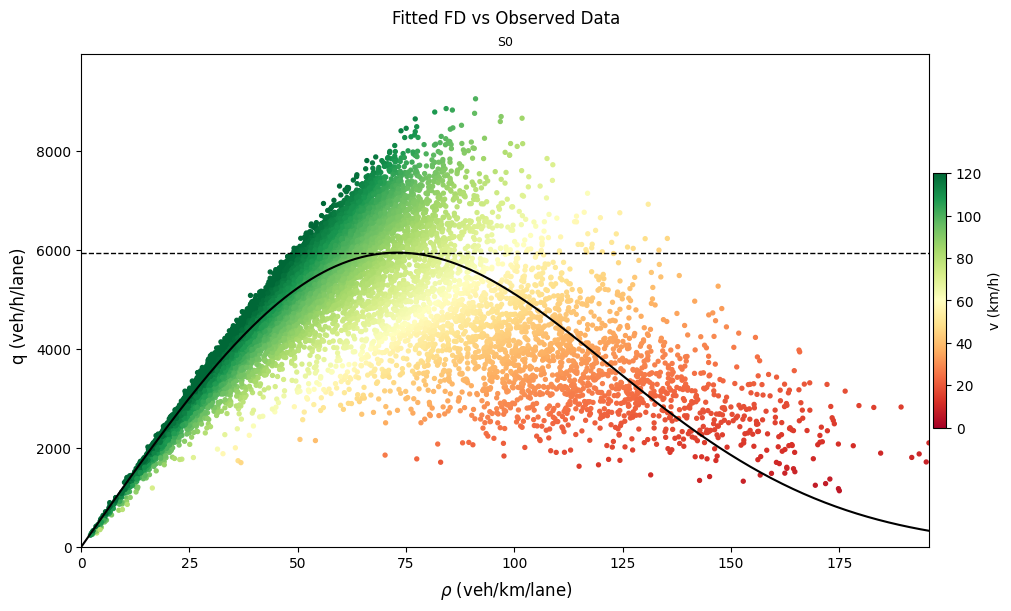

In [58]:
flattened_q_hat = q_hat.flatten()
flattened_rho_hat = rho_hat.flatten()

# Total (all-lane) density and flow, so allow a wider critical density than the per-lane default
params = fit_fd(flattened_rho_hat, flattened_q_hat, bounds={"p_crit": (15, 400)})
print("Fitted parameters:", params["params_at"]())
plot_fd_panels(params["params_at"](), flattened_rho_hat[:, np.newaxis], flattened_q_hat[:, np.newaxis], 
               panel_size=(10, 6), rho_max=flattened_rho_hat.max(), title="Fitted FD vs Observed Data");

In [59]:
print(f"Bounds on rho: {np.min(rho_hat)} to {np.max(rho_hat)}")
print(f"Bounds on q: {np.min(q_hat)} to {np.max(q_hat)}")
print(f"Bounds on v: {np.min(v_hat)} to {np.max(v_hat)}")

Bounds on rho: 2.13999975 to 195.689974
Bounds on q: 236.63671875 to 9049.08515625
Bounds on v: 6.483326749280186 to 135.72768561876867


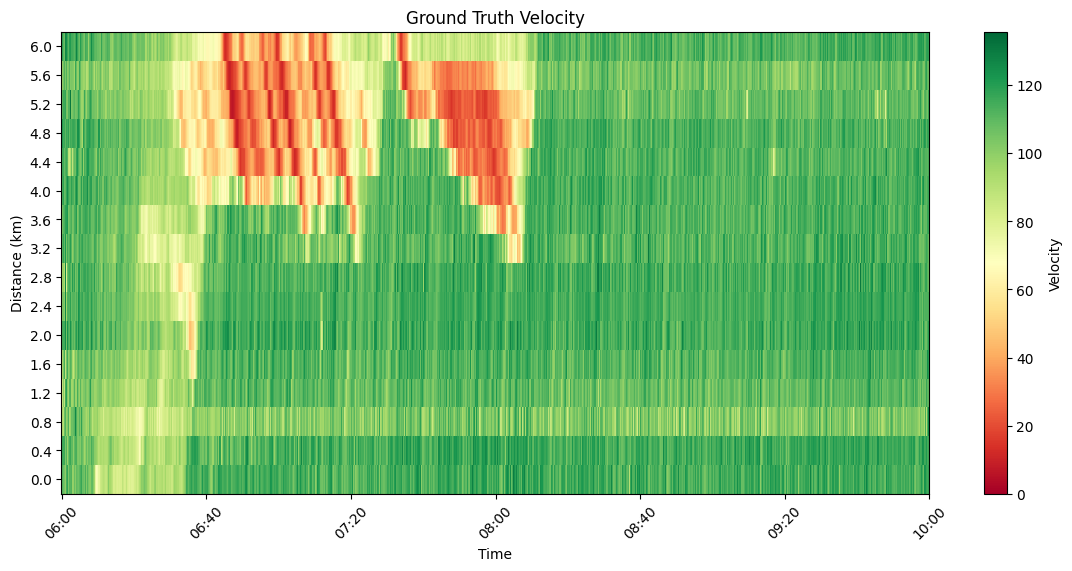

In [60]:
start_wallclock_time = 6
plt.figure(figsize=(14, 6))
plt.imshow(v_hat.T, aspect="auto", origin="lower", cmap="RdYlGn", interpolation="none", vmin=0)
plt.colorbar(label="Velocity")

# Convert time steps to wall clock time
time_steps = v_hat.shape[0]+1
time_ticks = list(range(0, time_steps, int(time_steps / 6)))
# Correct - each step is 10 seconds = 10/60 minutes
tick_minutes = [i * 10 / 60 for i in time_ticks]
time_labels = to_wallclock(tick_minutes, start_wallclock_time)

# Convert space steps to km
space_steps = v_hat.shape[1]
space_labels = [f"{(i * 400) / 1000:.1f}" for i in range(0, space_steps, int(space_steps / 10))]
space_ticks = list(range(0, space_steps, int(space_steps / 10)))

plt.xticks(time_ticks, time_labels, rotation=45)
plt.yticks(space_ticks, space_labels)

plt.title("Ground Truth Velocity")
plt.xlabel("Time")
plt.ylabel("Distance (km)")
plt.show()

In [61]:
T = 10 / 3600
l = 0.4
num_calibrated_segments = v_hat.shape[1] - 2
include_ramping = True
varylanes = False
smoothing = True

In [75]:
random.seed(1)
np.random.seed(1)

start = time.time()
results = run_calibration(
    rho_hat,
    q_hat,
    T,
    l,
    num_calibrated_segments=num_calibrated_segments,
    # sep_boundary_conditions=boundary_conditions,
    varylanes=varylanes,
    include_ramping=include_ramping,
    lane_mapping=lane_mapping,
    ramp_mapping=ramp_mapping,
    smoothing=smoothing,
    constraint_tol=1e-12,
    warmstart= None,
    tee = False, # Set to true to see the solver output
    robust_opt=None,
    time_varying_ramps=False,
    fixed_inflows=None,
)

print("Calibration took", time.time() - start, "seconds")

Calibration took 325.73693895339966 seconds


In [76]:
# Save initial and downstream conditions
import os

if not os.path.exists(RESULTS_DIR):
    os.makedirs(RESULTS_DIR)
    
np.save(f"{RESULTS_DIR}/upstream_flow.npy", smooth_inflow(q_hat[:, 0]) if smoothing else q_hat[:, 0])
np.save(f"{RESULTS_DIR}/downstream_density.npy", smooth_inflow(rho_hat[:, -1]) if smoothing else rho_hat[:, -1])

In [77]:
# Save everything
tau_array = results["tau"]
K_array = results["K"]
eta_high_array = results["eta_high"]
rho_crit_array = results["rho_crit"]
v_free_array = results["v_free"]
a_array = results["a"]
num_lanes_array = results["num_lanes"]
# if include_ramping:
    # gamma_array = results["gamma"]
beta_array = results["beta"]
r_inflow_array = results["r_inflow"]
v_pred_array = results["v_pred"]
rho_pred_array = results["rho_pred"]
q_array = v_pred_array * rho_pred_array

np.save(f"{RESULTS_DIR}/tau.npy", tau_array)
np.save(f"{RESULTS_DIR}/K.npy", K_array)
np.save(f"{RESULTS_DIR}/eta_high.npy", eta_high_array)
np.save(f"{RESULTS_DIR}/rho_crit.npy", rho_crit_array)
np.save(f"{RESULTS_DIR}/v_free.npy", v_free_array)
np.save(f"{RESULTS_DIR}/a.npy", a_array)
np.save(f"{RESULTS_DIR}/num_lanes.npy", num_lanes_array)
np.save(f"{RESULTS_DIR}/q_pred.npy", q_array)
np.save(f"{RESULTS_DIR}/v_pred.npy", v_pred_array)
np.save(f"{RESULTS_DIR}/rho_pred.npy", rho_pred_array)
# np.save("r_array.npy", r_array)
# if include_ramping:
    # np.save("gamma_array.npy", gamma_array)
np.save(f"{RESULTS_DIR}/beta_array.npy", beta_array)
np.save(f"{RESULTS_DIR}/r_inflow_array.npy", r_inflow_array)

(1440, 14)
(1440, 14)
(1440, 16)
14


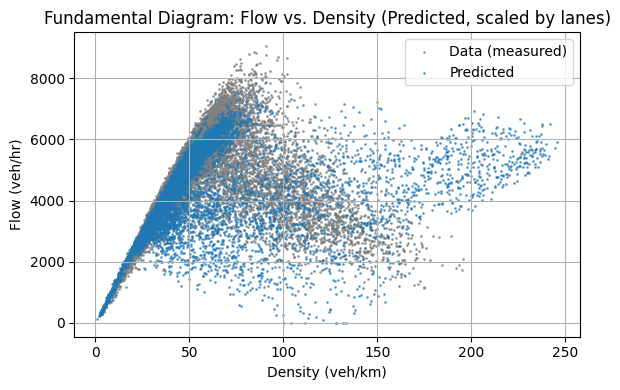

In [78]:
import matplotlib.pyplot as plt

# # Collect scaled predictions across all segments
all_rho_pred = rho_pred_array

print(all_rho_pred.shape)
all_v_pred = v_pred_array
all_q_pred = all_rho_pred * all_v_pred


# Stack predictions
all_rho_pred = np.hstack(all_rho_pred)
all_q_pred = np.hstack(all_q_pred)
all_v_pred = np.hstack(all_v_pred)

print(v_pred_array.shape)
print(v_hat.shape)
print(len(tau_array))

# assert np.all(v_pred_array[0,:] == v_hat[0,1:-1])
# assert np.all(v_pred_array[0,:] == v_hat[0,1:-1])
# Plot
plt.figure(figsize=(6, 4))
plt.scatter(rho_hat, q_hat, color="gray", alpha=0.7, s=1, label="Data (measured)")
plt.scatter(all_rho_pred, all_q_pred, alpha=0.6, s=1, label="Predicted")
plt.xlabel("Density (veh/km)")
plt.ylabel("Flow (veh/hr)")
plt.title("Fundamental Diagram: Flow vs. Density (Predicted, scaled by lanes)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

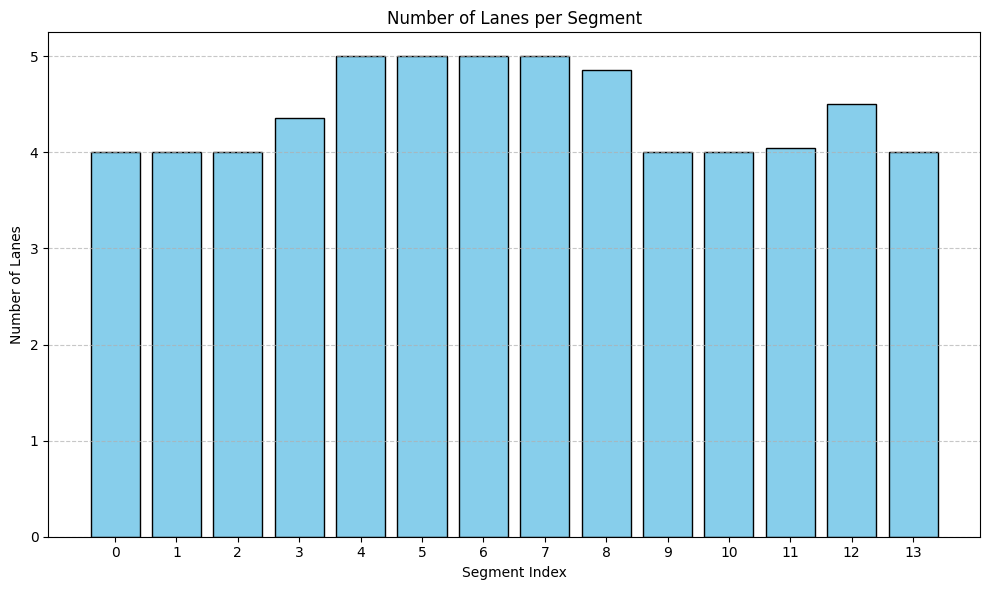

In [79]:
plt.figure(figsize=(10, 6))
plt.bar(
    np.arange(len(num_lanes_array)), num_lanes_array, color="skyblue", edgecolor="black"
)

plt.xlabel("Segment Index")
plt.ylabel("Number of Lanes")
plt.title("Number of Lanes per Segment")
plt.xticks(np.arange(len(num_lanes_array)))  # show all indices
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()

In [100]:
# Read parameters from RESULTS_DIR
tau_array = np.load(f"{RESULTS_DIR}/tau.npy")
K_array = np.load(f"{RESULTS_DIR}/K.npy")
eta_high_array = np.load(f"{RESULTS_DIR}/eta_high.npy")
v_free_array = np.load(f"{RESULTS_DIR}/v_free.npy")
rho_crit_array = np.load(f"{RESULTS_DIR}/rho_crit.npy")
a_array = np.load(f"{RESULTS_DIR}/a.npy")
rho_pred_array = np.load(f"{RESULTS_DIR}/rho_pred.npy")
v_pred_array = np.load(f"{RESULTS_DIR}/v_pred.npy")
beta_array = np.load(f"{RESULTS_DIR}/beta_array.npy")
r_inflow_array = np.load(f"{RESULTS_DIR}/r_inflow_array.npy")

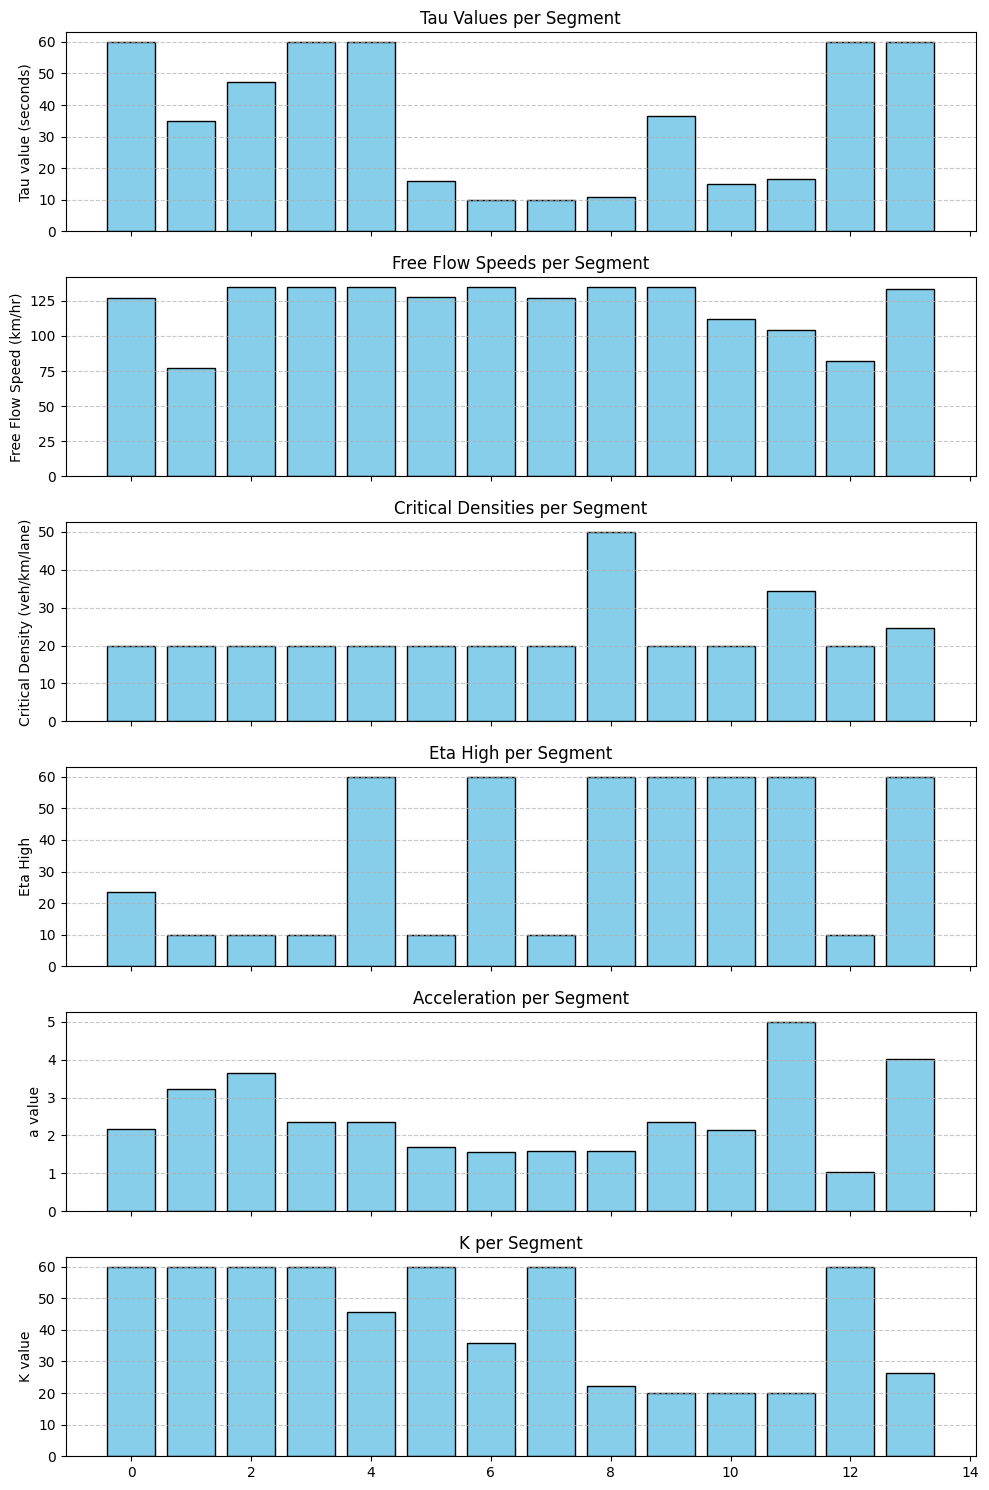

In [101]:
# Plot parameters in bar chart, show default value
fig, axes = plt.subplots(6, 1, figsize=(10, 15), sharex=True)
axes[0].bar(
    np.arange(len(tau_array)), tau_array*3600, color="skyblue", edgecolor="black"
)

axes[0].set_ylabel("Tau value (seconds)")
axes[0].set_title("Tau Values per Segment")
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

axes[1].bar(
    np.arange(len(v_free_array)), v_free_array, color="skyblue", edgecolor="black"
)
axes[1].set_ylabel("Free Flow Speed (km/hr)")
axes[1].set_title("Free Flow Speeds per Segment")
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

axes[2].bar(
    np.arange(len(rho_crit_array)), rho_crit_array, color="skyblue", edgecolor="black"
)
axes[2].set_ylabel("Critical Density (veh/km/lane)")
axes[2].set_title("Critical Densities per Segment")
axes[2].grid(axis="y", linestyle="--", alpha=0.7)

axes[3].bar(
    np.arange(len(eta_high_array)), eta_high_array, color="skyblue", edgecolor="black"
)
axes[3].set_ylabel("Eta High")
axes[3].set_title("Eta High per Segment")
axes[3].grid(axis="y", linestyle="--", alpha=0.7)

axes[4].bar(
    np.arange(len(a_array)), a_array, color="skyblue", edgecolor="black"
)
axes[4].set_ylabel("a value")
axes[4].set_title("Acceleration per Segment")
axes[4].grid(axis="y", linestyle="--", alpha=0.7)

axes[5].bar(
    np.arange(len(K_array)), K_array, color="skyblue", edgecolor="black"
)
axes[5].set_ylabel("K value")
axes[5].set_title("K per Segment")
axes[5].grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()

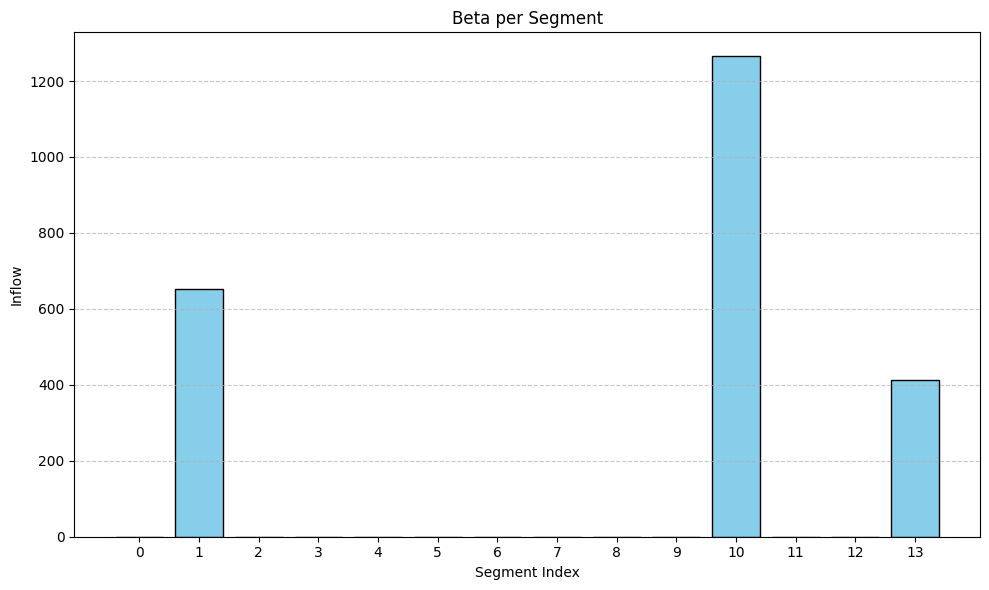

In [102]:
if include_ramping:
    plt.figure(figsize=(10, 6))
    plt.bar(np.arange(len(r_inflow_array)), r_inflow_array, color="skyblue", edgecolor="black")

    plt.xlabel("Segment Index")
    plt.ylabel("Inflow")
    plt.title("Beta per Segment")
    plt.xticks(np.arange(len(num_lanes_array)))  # show all indices
    plt.grid(axis="y", linestyle="--", alpha=0.7)

    plt.tight_layout()

In [103]:
# print(all_v_pred.shape)

q_array = rho_pred_array * v_pred_array
print("rho mape", mape(rho_hat[:, 1:-1], rho_pred_array))
print("q mape", mape(q_hat[:, 1:-1], q_array))
print("v mape", mape(v_hat[:, 1:-1], v_pred_array))
print("----------------")
print("rho rmse", rmse(rho_hat[:, 1:-1], rho_pred_array))
print("q rmse", rmse(q_hat[:, 1:-1], q_array))
print("v rmse", rmse(v_hat[:, 1:-1], v_pred_array))

rho mape 32.21719348780559
q mape 29.273971568610875
v mape 11.354918970603997
----------------
rho rmse 23.425117726462073
q rmse 1428.2014828705462
v rmse 12.088932462684161


In [104]:
print("Simulating with calibrated parameters...")
# stop printing in scientific notation
np.set_printoptions(suppress=True)

num_calibrated_segments = rho_hat.shape[1] - 2
scaled_rho_hat = rho_hat[:, 1:-1] / lane_map

params = METANET_Params(path=RESULTS_DIR, num_segments=num_calibrated_segments).get_params()
#mpc_params = METANET_Params(path="old_code/itsc_final/mpc_calibration_results", control_h=1, num_timesteps=360).get_params()

rho_sim, v_sim, _, tts_sim = run_metanet_sim(
    T, 
    l, 
    init_traffic_state,
    data_inflow,
    downstream_density/lane_map[-1],
    params,
    vsl_speeds=None,
    lanes=lane_mapping, #{i: num_lanes_array[i] for i in range(num_calibrated_segments)},
    plotting=True,
    real_data=True
)

Simulating with calibrated parameters...


Pred shape: (1440, 14)
True shape: (1440, 14)
Max true density: 195.689974


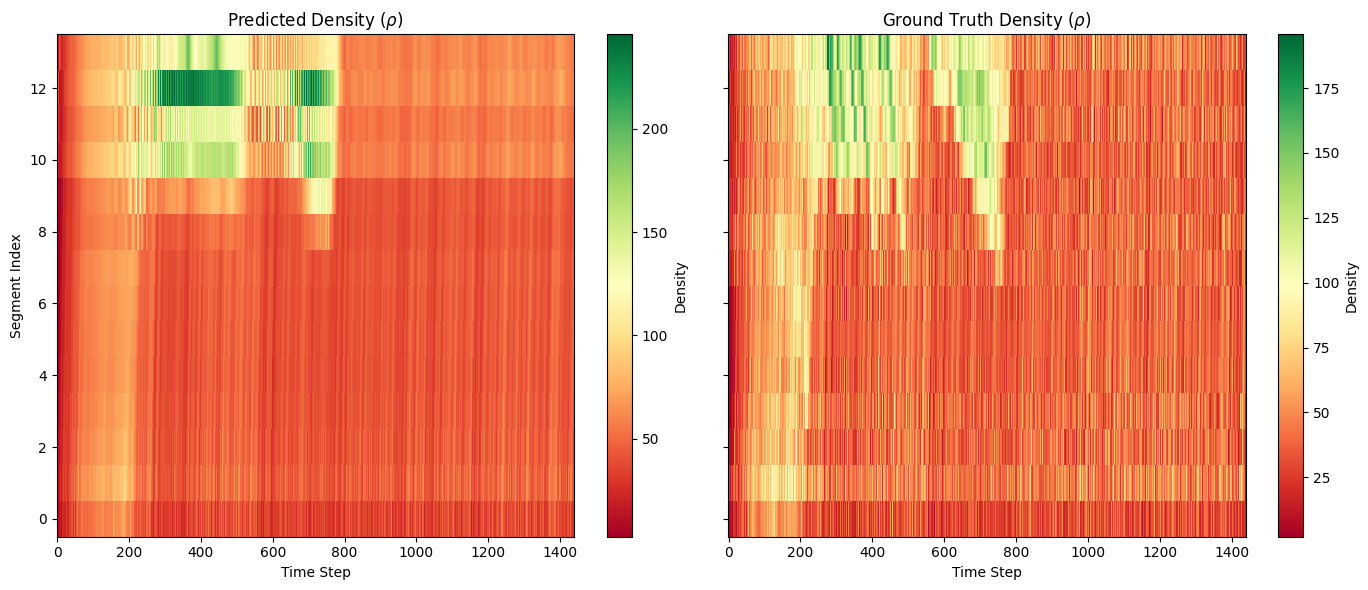

In [105]:
rho_plot_pred = rho_pred_array
rho_plot_true = rho_hat[:, 1:-1]

print("Pred shape:", rho_plot_pred.shape)
print("True shape:", rho_plot_true.shape)
print("Max true density:", np.max(rho_plot_true))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# --- Prediction ---
im0 = axes[0].imshow(
    rho_plot_pred.T, aspect="auto", origin="lower", cmap="RdYlGn", interpolation="none"
)
axes[0].set_xlabel("Time Step")
axes[0].set_ylabel("Segment Index")
axes[0].set_title("Predicted Density ($\\rho$)")
fig.colorbar(im0, ax=axes[0], label="Density")

# --- Ground Truth ---
im1 = axes[1].imshow(
    rho_plot_true.T, aspect="auto", origin="lower", cmap="RdYlGn", interpolation="none"
)
axes[1].set_xlabel("Time Step")
axes[1].set_title("Ground Truth Density ($\\rho$)")
fig.colorbar(im1, ax=axes[1], label="Density")

plt.tight_layout()
plt.show()

Pred shape: (1440, 14)
True shape: (1440, 14)
Max true density: 135.72768561876867


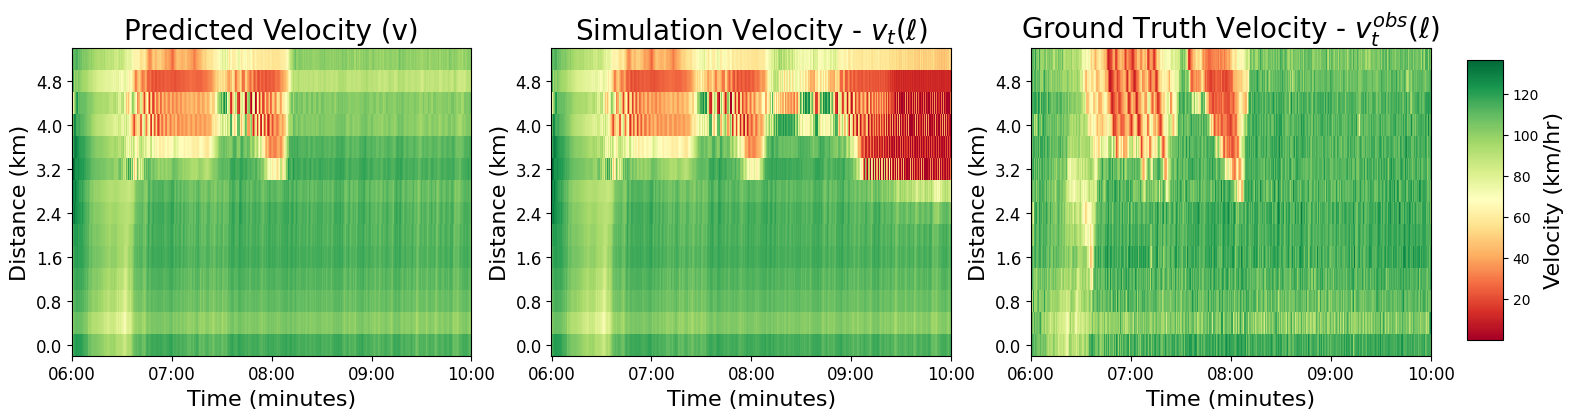

In [106]:
# print(v_pred_array[0, :])
# print(v_pred_array[1, :])
v_plot_pred = np.load(f"{RESULTS_DIR}/v_pred.npy")
v_plot_true = v_hat[:, 1:-1]

print("Pred shape:", v_plot_pred.shape)
print("True shape:", v_plot_true.shape)
print("Max true density:", np.max(v_plot_true))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# --- Compute common color scale ---
vmin = min(
    np.min(v_plot_pred),
    np.min(v_sim),
    np.min(v_plot_true),
)
vmax = max(
    np.max(v_plot_pred),
    np.max(v_sim),
    np.max(v_plot_true),
)

# --- Prediction ---
im0 = axes[0].imshow(
    v_plot_pred.T,
    aspect="auto",
    origin="lower",
    cmap="RdYlGn",
    interpolation="none",
    vmin=vmin,
    vmax=vmax,
)
axes[0].set_xlabel("Time Step")
axes[0].set_ylabel("Segment Index")
axes[0].set_title("Predicted Velocity (v)")

# --- Simulation ---
im1 = axes[1].imshow(
    v_sim.T,
    aspect="auto",
    origin="lower",
    cmap="RdYlGn",
    interpolation="none",
    vmin=vmin,
    vmax=vmax,
)
axes[1].set_xlabel("Time Step")
axes[1].set_title("Simulation Velocity - $v_t(\\ell)$", fontsize=20)

# --- Ground Truth ---
im2 = axes[2].imshow(
    v_plot_true.T,
    aspect="auto",
    origin="lower",
    cmap="RdYlGn",
    interpolation="none",
    vmin=vmin,
    vmax=vmax,
)
axes[2].set_xlabel("Time Step")
axes[2].set_title(
    "Ground Truth Velocity - $v^{obs}_t(\\ell)$",
    fontsize=20,
)

# ---- One shared colorbar in its own axis ----
# Make room on the right for the colorbar
fig.subplots_adjust(right=0.88)

# [left, bottom, width, height] in figure coordinates
cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im0, cax=cbar_ax)
cbar.set_label("Velocity (km/hr)", fontsize=16)

# Convert x label to minutes
for ax in axes:
    ax.set_xlabel("Time (minutes)")

# Convert x ticks to minutes
num_time_steps = v_plot_pred.shape[0]+1
time_step_indices = np.arange(0, num_time_steps, max(1, num_time_steps // 4))
time_step_labels = [f"{(i * T * 60):.0f}" for i in time_step_indices]
time_minutes = time_step_indices * T * 60
time_step_labels = to_wallclock(time_minutes, start_wallclock_time)
for ax in axes:
    ax.set_xticks(time_step_indices)
    ax.set_xticklabels(time_step_labels)

# Convert y axis to kilometers
for ax in axes:
    num_segments = v_plot_pred.shape[1]
    segment_indices = np.arange(0, num_segments, max(1, num_segments // 6))
    segment_labels = [f"{(i * l):.1f}" for i in segment_indices]
    ax.set_yticks(segment_indices)
    ax.set_yticklabels(segment_labels)
    ax.set_ylabel("Distance (km)")

# label font size
for ax in axes:
    ax.title.set_fontsize(20)
    ax.xaxis.label.set_fontsize(16)
    ax.yaxis.label.set_fontsize(16)
    ax.tick_params(axis='both', which='major', labelsize=12)    

plt.show()


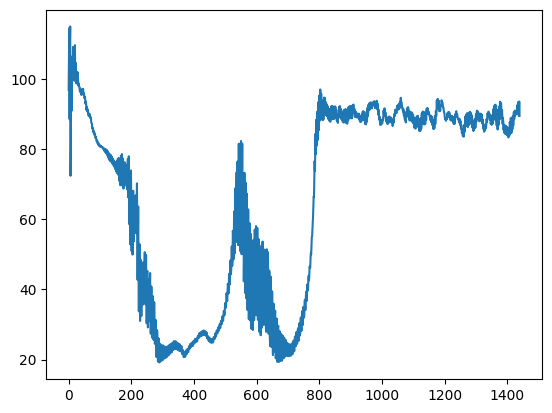

In [107]:
plt.plot(v_plot_pred[:, -2])

In [95]:
print("v mape", mape(v_hat[:, 1:-1], v_sim[0:-1, :]))
print("v model mismatch", mape(v_plot_pred, v_sim[0:-1, :]))

v mape 19.35437998171337
v model mismatch 1430.4942479350061


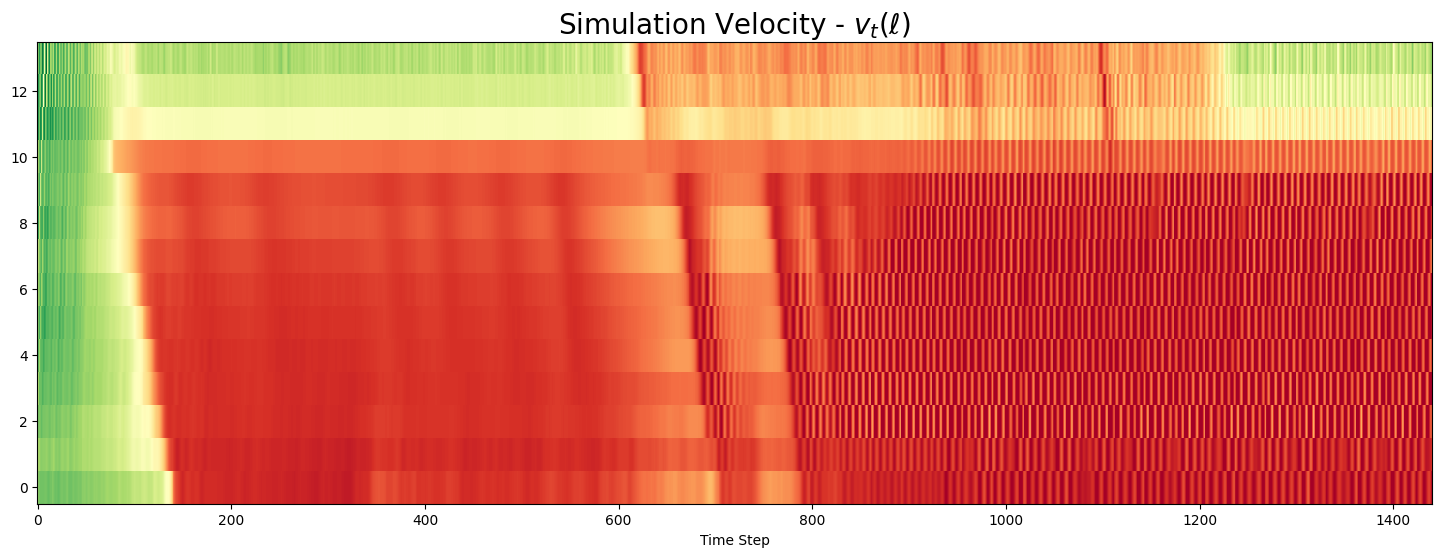

In [221]:
# Plot only v_sim
# --- Simulation ---
fig, axes = plt.subplots(1, 1, figsize=(18, 6))

im1 = axes.imshow(
    v_sim.T,
    aspect="auto",
    origin="lower",
    cmap="RdYlGn",
    interpolation="none",
)
axes.set_xlabel("Time Step")
axes.set_title("Simulation Velocity - $v_t(\\ell)$", fontsize=20)

plt.show()

In [197]:
np.save(f"{RESULTS_DIR}/v_sim.npy", v_sim)

In [198]:
print("rho mape", mape(rho_hat[:, 1:-1], rho_sim[0:-1, :] * np.array(lane_map)))
print("v mape", mape(v_hat[:, 1:-1], v_sim[0:-1, :]))
print("----------------")
print("rho rmse", rmse(rho_hat[:, 1:-1], rho_sim[0:-1, :] * np.array(lane_map)))
print("v rmse", rmse(v_hat[:, 1:-1], v_sim[0:-1, :]))

rho mape 26.637950782011593
v mape 38.89796114033239
----------------
rho rmse 29.790466561812927
v rmse 22.32599680058538


In [ ]:
params =  METANET_Params(path=RESULTS_DIR, num_segments=num_calibrated_segments).get_params()
# num_lanes_array = np.load(os.path.join(test_dir, "num_lanes.npy"))


epsilons = [0, 1e-13, 1e-7, 1e-4, 0.01, 0.1, 1, 5]
eval_results = eval_robustness_static(v_hat[:, 1:-1], params, data_inflow, downstream_density/lane_map[-1], init_traffic_state, 
                                    lanes=lane_mapping, T=T, l=l, percent_noises=epsilons, rho_gt=rho_hat[:, 1:-1],
                                    plotting_dir=RESULTS_DIR, save_results=True)

# eval_results = eval_robustness_dynamic(v_hat[:, 1:-1], 1, "mpc_calibration_results", data_inflow, downstream_density, 
#                                             init_traffic_state, T=T, l=l, percent_noises=epsilons, save_results=True)
    


In [ ]:
# plot error over time between prediction and simulation
plt.figure(figsize=(12, 6))
plt.plot(np.abs(v_plot_pred - v_sim[0:-1, :]).mean(axis=1))
plt.xlabel('Time (min)')
plt.ylabel('Error')
plt.title('Simulation vs Calibration Error Over Time')
plt.legend()
plt.grid()
plt.show()

In [ ]:
# plot error over time between prediction and simulation
plt.figure(figsize=(12, 6))
plt.plot(np.abs(v_hat[:, 1:-1] - v_sim[0:-1, :]).mean(axis=1))
plt.xlabel('Time (min)')
plt.ylabel('Error')
plt.title('Simulation vs GT MAE Over Time')
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Plot inflow over time
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

g_fontsize = 21
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": "Times New Roman",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,
    "text.usetex": False,
    "font.size": g_fontsize,
    "axes.labelsize": g_fontsize,
    "xtick.labelsize": g_fontsize - 2,
    "ytick.labelsize": g_fontsize - 2,
    "legend.fontsize": g_fontsize - 1,
})

plt.figure(figsize=(12, 6))
plt.plot(data_inflow, label='Inflow', linewidth=3, color='gray')

plt.xlabel('Time')
plt.ylabel('Inflow (veh/hr)')

# Assume data_inflow covers exactly 8:00 AM to 9:00 AM
n = len(data_inflow)

tick_positions = np.linspace(0, n - 1, 5)
tick_labels = ['8:00', '8:15', '8:30', '8:45', '9:00']

plt.xticks(tick_positions, tick_labels)
plt.grid()
plt.savefig('figs/itsc2026/inflow_over_time.pdf', bbox_inches='tight')
plt.show()

In [ ]:
rho_plot_pred = rho_pred_array * v_pred_array
rho_plot_true = q_hat[:, 1:-1]

print("Pred shape:", rho_plot_pred.shape)
print("True shape:", rho_plot_true.shape)
print("Max true density:", np.max(rho_plot_true))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# --- Prediction ---
im0 = axes[0].imshow(
    rho_plot_pred.T, aspect="auto", origin="lower", cmap="RdYlGn", interpolation="none"
)
axes[0].set_xlabel("Time Step")
axes[0].set_ylabel("Segment Index")
axes[0].set_title("Predicted Flow ($\\rho$)")
fig.colorbar(im0, ax=axes[0], label="Flow")

# --- Ground Truth ---
im1 = axes[1].imshow(
    rho_plot_true.T, aspect="auto", origin="lower", cmap="RdYlGn", interpolation="none"
)
axes[1].set_xlabel("Time Step")
axes[1].set_title("Ground Truth Flow ($\\rho$)")
fig.colorbar(im1, ax=axes[1], label="Flow")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
# Plotting
plt.figure(figsize=(12, 5))

# Flow vs timesteps
plt.subplot(1, 2, 1)
plt.plot(data_inflow, label="Initial Flow (smoothed)")
plt.xlabel("Timestep")
plt.ylabel("Flow [veh/h]")
plt.title("Upstream Inflow vs Timesteps")
plt.legend()

# Density vs timesteps
plt.subplot(1, 2, 2)
plt.plot(downstream_density, color="orange", label="Downstream Density (smoothed)")
plt.xlabel("Timestep")
plt.ylabel("Density [veh/km]")
plt.title("Downstream Density vs Timesteps")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
def get_velocity_heatmap(v_hat, v_pred, q_hat, q_pred, rho_hat, rho_pred):
    shortened_v_hat = v_hat[:, 1:-1]
    shortened_rho_hat = rho_hat[:, 1:-1]
    shortened_q_hat = q_hat[:, 1:-1]
    # Determine some set of 3 scalars for each of q, rho, v to make a unified map
    v_diff = (shortened_v_hat - v_pred) / np.max(shortened_v_hat)
    rho_diff = (shortened_rho_hat - rho_pred) / np.max(shortened_rho_hat)
    q_diff = (shortened_q_hat - q_pred) / np.max(shortened_q_hat)

    diff = v_diff + rho_diff + q_diff
    fig, ax = plt.subplots(figsize=(14, 6))

    im = ax.imshow(
        diff.T,
        aspect="auto",
        origin="lower",
        cmap="viridis",
        interpolation="none",
        vmin=0,
    )
    ax.set_xlabel("Time Step")
    ax.set_ylabel("Segment Index")
    ax.set_title("Absolute Inflow Difference |Pred - True|")
    fig.colorbar(im, ax=ax, label="|Flow Difference|")
    plt.show()


get_velocity_heatmap(v_hat, v_pred_array, q_hat, q_array, rho_hat, rho_pred_array)